In [1]:
# Step 1 — Install only the extra packages; keep Colab's own PyTorch/CUDA stack.
!pip -q install lpips scikit-image pillow pandas
print("Packages installed.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.8/53.8 kB 3.3 MB/s eta 0:00:00
Packages installed.


In [2]:
# Step 2 — Imports, reproducibility, paths, configuration.

import os, io, math, time, random, zipfile, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageFilter

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms

from google.colab import files
from IPython.display import display, HTML

import lpips
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU -- go to Runtime > Change runtime type > GPU for a faster attack loop.")

WORK = Path("/content/taa_deepfake_defense")
INPUTS = WORK / "inputs"
OUTPUTS = WORK / "outputs"
for p in [INPUTS, OUTPUTS]:
    p.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = 256
GRID_SIZE  = 8     # image is split into an 8x8 grid of patches -> patch size = 256/8 = 32px
TAIL_RANK  = 2     # keep the 2 smallest singular directions per patch (low-energy texture)
SVD_AMPLIFICATION = 0.05   # scale of the SVD-tail initial perturbation, before optimisation

# FIX (see Step 2 markdown): EPSILON is now the ONLY, single perturbation budget, in the
# generator's native [-1,1] range. 0.05 corresponds to roughly 6-7 / 255 -- a realistic,
# still-close-to-invisible adversarial budget. The old file multiplied epsilon by a SEPARATE
# clamp of 0.1, giving an effective budget of 0.005 -- smaller than one 8-bit quantisation step.
EPSILON = 0.05
NUM_STEPS = 50
LEARNING_RATE = 0.01
COLOR_NOISE_STD = 0.01     # small fixed global colour-channel tint, kept well inside EPSILON

USE_EOT = True
EOT_SAMPLES = 3

ATTRIBUTES = ["Black_Hair", "Blond_Hair", "Brown_Hair", "Male", "Young"]
TARGET_ATTRIBUTE = "Blond_Hair"
TARGET_VALUE = 1

print("Configuration ready.")

Device: cuda
GPU: Tesla T4
Configuration ready.


In [3]:
STAR_REPO = Path("/content/stargan")
if not STAR_REPO.exists():
    print("Cloning official StarGAN repository (for its download script only)...")
    subprocess.run(["git", "clone", "-q", "https://github.com/yunjey/stargan.git", str(STAR_REPO)], check=True)
else:
    print("StarGAN repository already present.")

CKPT_DIR = STAR_REPO / "stargan_celeba_256" / "models"
CKPT_DIR.mkdir(parents=True, exist_ok=True)
ckpt = CKPT_DIR / "200000-G.ckpt"
checkpoint_source = "official StarGAN 256x256"

if not ckpt.exists():
    print("Trying the official pretrained 256x256 checkpoint download...")
    result = subprocess.run(["bash", "download.sh", "pretrained-celeba-256x256"],
                            cwd=str(STAR_REPO), text=True, capture_output=True)
    if result.returncode != 0:
        print("Official 256x256 download failed.")
        print(result.stderr[-1000:])

if not ckpt.exists():
    print("Trying a mirrored fallback checkpoint (UNVERIFIED -- may not match the architecture below)...")
    fallback = CKPT_DIR / "200000-G-fallback.ckpt"
    fallback_url = ("https://huggingface.co/RuoyuChen/Facial_Attributes_Obfuscation/"
                    "resolve/main/stargan_celeba/models/200000-G.ckpt?download=true")
    result = subprocess.run(["wget", "-q", "-O", str(fallback), fallback_url], text=True, capture_output=True)
    if result.returncode == 0 and fallback.exists() and fallback.stat().st_size > 1_000_000:
        ckpt = fallback
        checkpoint_source = "mirrored fallback checkpoint (unverified compatibility)"
    else:
        print(result.stderr[-1000:] if result.stderr else "wget failed silently.")

if not ckpt.exists():
    print("Could not obtain a checkpoint automatically.")
    print("  Run the NEXT cell to upload a 200000-G.ckpt file yourself, OR this demo will")
    print("  fall back to an untrained placeholder network (pipeline-only, not a real deepfake test).")

G_PATH = ckpt if ckpt.exists() else None
if G_PATH:
    print("Using generator checkpoint:", G_PATH)
    print("Checkpoint source:", checkpoint_source)
    print("Size (MB):", round(G_PATH.stat().st_size / (1024**2), 2))

Cloning official StarGAN repository (for its download script only)...
Trying the official pretrained 256x256 checkpoint download...
Using generator checkpoint: /content/stargan/stargan_celeba_256/models/200000-G.ckpt
Checkpoint source: official StarGAN 256x256
Size (MB): 32.2


In [4]:
# OPTIONAL -- only run this if the cell above did NOT print "Using generator checkpoint".
if G_PATH is None:
    print("Select your 200000-G.ckpt file...")
    up = files.upload()
    for fn in up.keys():
        import shutil
        dest = CKPT_DIR / "200000-G.ckpt"
        shutil.move(fn, dest)
        G_PATH = dest
        checkpoint_source = "manually uploaded"
        print("Saved to", G_PATH)
        break

In [5]:
class ResidualBlock(nn.Module):
    def __init__(self, dim_in, dim_out):
        super().__init__()
        self.main = nn.Sequential(
            nn.Conv2d(dim_in, dim_out, kernel_size=3, stride=1, padding=1, bias=False),
            nn.InstanceNorm2d(dim_out, affine=True, track_running_stats=True),
            nn.ReLU(inplace=True),
            nn.Conv2d(dim_out, dim_out, kernel_size=3, stride=1, padding=1, bias=False),
            nn.InstanceNorm2d(dim_out, affine=True, track_running_stats=True),
        )
    def forward(self, x):
        return x + self.main(x)

class StarGANGenerator(nn.Module):
    def __init__(self, conv_dim=64, c_dim=5, repeat_num=6):
        super().__init__()
        layers = [nn.Conv2d(3 + c_dim, conv_dim, kernel_size=7, stride=1, padding=3, bias=False),
                  nn.InstanceNorm2d(conv_dim, affine=True, track_running_stats=True),
                  nn.ReLU(inplace=True)]
        curr_dim = conv_dim
        for _ in range(2):
            layers += [nn.Conv2d(curr_dim, curr_dim * 2, kernel_size=4, stride=2, padding=1, bias=False),
                       nn.InstanceNorm2d(curr_dim * 2, affine=True, track_running_stats=True),
                       nn.ReLU(inplace=True)]
            curr_dim *= 2
        for _ in range(repeat_num):
            layers.append(ResidualBlock(curr_dim, curr_dim))
        for _ in range(2):
            layers += [nn.ConvTranspose2d(curr_dim, curr_dim // 2, kernel_size=4, stride=2, padding=1, bias=False),
                       nn.InstanceNorm2d(curr_dim // 2, affine=True, track_running_stats=True),
                       nn.ReLU(inplace=True)]
            curr_dim //= 2
        layers += [nn.Conv2d(curr_dim, 3, kernel_size=7, stride=1, padding=3, bias=False), nn.Tanh()]
        self.main = nn.Sequential(*layers)

    def forward(self, x, c):
        c_map = c.view(c.size(0), c.size(1), 1, 1).repeat(1, 1, x.size(2), x.size(3))
        return self.main(torch.cat([x, c_map], dim=1))

class PlaceholderGenerator(nn.Module):
    """FALLBACK ONLY, used if no checkpoint could be obtained at all. Untrained -- proves the
    pipeline runs end to end, does NOT demonstrate a real deepfake being disrupted."""
    def __init__(self, c_dim=5):
        super().__init__()
        self.c_dim = c_dim
        self.net = nn.Sequential(nn.Conv2d(3 + c_dim, 32, 4, 2, 1), nn.ReLU(),
                                 nn.Conv2d(32, 64, 4, 2, 1), nn.ReLU(),
                                 nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(),
                                 nn.ConvTranspose2d(32, 3, 4, 2, 1), nn.Tanh())
    def forward(self, x, c):
        c_map = c.view(c.size(0), c.size(1), 1, 1).repeat(1, 1, x.size(2), x.size(3))
        return self.net(torch.cat([x, c_map], dim=1))

USING_REAL_STARGAN = False
if G_PATH is not None:
    try:
        G = StarGANGenerator(conv_dim=64, c_dim=5, repeat_num=6).to(DEVICE)
        state = torch.load(G_PATH, map_location=DEVICE, weights_only=False)
        if isinstance(state, dict) and "state_dict" in state:
            state = state["state_dict"]
        try:
            G.load_state_dict(state, strict=True)
        except Exception as e_strict:
            print("Strict load failed (", type(e_strict).__name__, ") -- trying non-strict load.")
            missing, unexpected = G.load_state_dict(state, strict=False)
            if len(missing) > len(dict(G.named_parameters())) // 2:
                raise RuntimeError("Checkpoint does not match this architecture closely enough.")
            print("Loaded non-strictly. Missing:", len(missing), "Unexpected:", len(unexpected))
        G.eval()
        for p in G.parameters():
            p.requires_grad_(False)
        USING_REAL_STARGAN = True
        print("StarGAN generator loaded successfully from:", checkpoint_source)
        print("Parameters:", sum(p.numel() for p in G.parameters()))
    except Exception as e:
        print("Failed to load StarGAN (", type(e).__name__, ":", str(e), "). Falling back to placeholder.")

if not USING_REAL_STARGAN:
    G = PlaceholderGenerator(c_dim=5).to(DEVICE).eval()
    for p in G.parameters():
        p.requires_grad_(False)
    print("WARNING: using an UNTRAINED placeholder generator. The pipeline still runs, but")
    print("         disruption numbers are only meaningful against a REAL generator.")

StarGAN generator loaded successfully from: official StarGAN 256x256
Parameters: 8430528


Saving Krishiv-Photo-Sept-2026.jpg to Krishiv-Photo-Sept-2026.jpg
Saved: /content/taa_deepfake_defense/inputs/Krishiv-Photo-Sept-2026.jpg


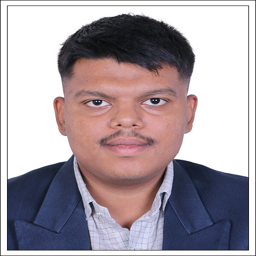

In [6]:
uploaded = files.upload()
if not uploaded:
    raise RuntimeError("No image was uploaded.")

first_name = next(iter(uploaded))
input_path = INPUTS / first_name
with open(input_path, "wb") as f:
    f.write(uploaded[first_name])

print("Saved:", input_path)
display(Image.open(input_path).convert("RGB").resize((256, 256)))

Tensor shape: (1, 3, 256, 256)


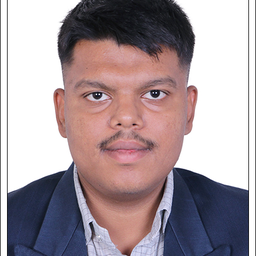

In [7]:
def center_square_crop(pil_img):
    w, h = pil_img.size
    side = min(w, h)
    left, top = (w - side) // 2, (h - side) // 2
    return pil_img.crop((left, top, left + side, top + side))

def load_image_tensor(path, image_size=256):
    img = Image.open(path)
    img = ImageOps.exif_transpose(img).convert("RGB")
    img = center_square_crop(img)
    img = img.resize((image_size, image_size), Image.Resampling.LANCZOS)
    x = transforms.ToTensor()(img).unsqueeze(0).to(DEVICE)
    return img, x * 2.0 - 1.0   # [0,1] -> [-1,1]

def tensor_to_pil(x):
    x = x.detach().clamp(-1, 1)
    x = ((x + 1.0) / 2.0 * 255.0).round().byte()
    return Image.fromarray(x.squeeze(0).permute(1, 2, 0).cpu().numpy())

def tensor_to_np01(x):
    x = x.detach().clamp(-1, 1)
    return ((x + 1.0) / 2.0).squeeze(0).permute(1, 2, 0).cpu().numpy()

def display_pair(a, b, titles=("A", "B"), figsize=(10, 5)):
    fig, ax = plt.subplots(1, 2, figsize=figsize)
    ax[0].imshow(tensor_to_np01(a)); ax[0].set_title(titles[0]); ax[0].axis("off")
    ax[1].imshow(tensor_to_np01(b)); ax[1].set_title(titles[1]); ax[1].axis("off")
    plt.tight_layout(); plt.show()

def psnr01(a, b):
    """PSNR of two [-1,1]-range tensors, computed in the equivalent [0,1] scale."""
    a01 = (a.detach().clamp(-1, 1) + 1) / 2
    b01 = (b.detach().clamp(-1, 1) + 1) / 2
    mse = F.mse_loss(a01, b01).item()
    return 99.0 if mse <= 1e-12 else 10 * math.log10(1.0 / mse)

_, x_clean = load_image_tensor(input_path, IMAGE_SIZE)
print("Tensor shape:", tuple(x_clean.shape))
display(tensor_to_pil(x_clean).resize((256, 256)))

Target attribute: Blond_Hair = 1  vector: [[0. 1. 0. 0. 0.]]


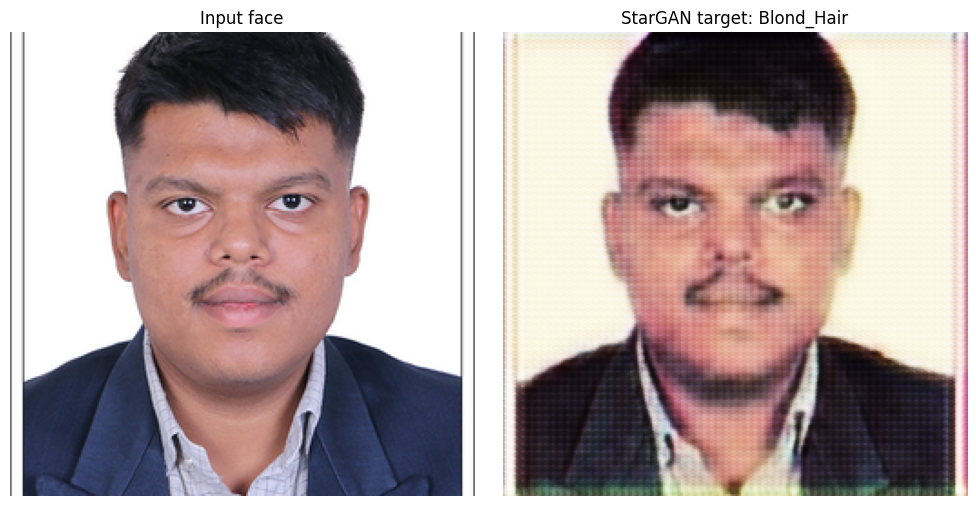

In [8]:
def make_target_condition(attribute, value=1):
    if attribute not in ATTRIBUTES:
        raise ValueError(f"Unknown attribute: {attribute}")
    c = torch.zeros((1, len(ATTRIBUTES)), dtype=torch.float32, device=DEVICE)
    c[0, ATTRIBUTES.index(attribute)] = float(value)
    return c

c_target = make_target_condition(TARGET_ATTRIBUTE, TARGET_VALUE)
print("Target attribute:", TARGET_ATTRIBUTE, "=", TARGET_VALUE, " vector:", c_target.cpu().numpy())

with torch.no_grad():
    y_clean_ref = G(x_clean, c_target)

display_pair(x_clean, y_clean_ref, titles=("Input face", f"StarGAN target: {TARGET_ATTRIBUTE}"))

In [9]:
@torch.no_grad()
def _patchify(x, patch):
    return x.unfold(2, patch, patch).unfold(3, patch, patch)   # (B,C,g,g,patch,patch)

def _unpatchify(t):
    B, C, g1, g2, p, _ = t.shape
    return t.permute(0, 1, 2, 4, 3, 5).reshape(B, C, g1 * p, g2 * p)

@torch.no_grad()
def svd_tail_basis(x, grid=8, tail_rank=2):
    """SVD of the CLEAN image's patches, computed ONCE (never differentiated -- SVD backward
    is numerically unstable, and recomputing every optimisation step would also be wasteful)."""
    B, C, H, W = x.shape
    patch = H // grid
    P = _patchify(x, patch).contiguous().float()
    U, S, Vh = torch.linalg.svd(P.cpu(), full_matrices=False)
    U, S, Vh = U.to(x.device), S.to(x.device), Vh.to(x.device)
    k = min(tail_rank, S.shape[-1])
    Ub, Sb, Vhb = U[..., :, -k:], S[..., -k:], Vh[..., -k:, :]
    return Ub, Sb, Vhb, patch

def svd_tail_initialize(x, grid=8, tail_rank=2, amplification=0.05):
    """Low-energy texture reconstruction, used as the STARTING perturbation before optimisation."""
    Ub, Sb, Vhb, patch = svd_tail_basis(x, grid, tail_rank)
    tail = (Ub * Sb.unsqueeze(-2)) @ Vhb
    tail_img = _unpatchify(tail)
    scale = tail_img.abs().amax(dim=(1, 2, 3), keepdim=True).clamp_min(1e-8)
    return amplification * tail_img / scale

def project_to_tail(t, Ub, Vhb, patch):
    """Orthogonal projection of an image-shaped tensor onto span{u_i v_j^T} per patch."""
    Pt = _patchify(t, patch)
    coef = Ub.transpose(-1, -2) @ Pt @ Vhb.transpose(-1, -2)
    return _unpatchify(Ub @ coef @ Vhb)

print("SVD-tail utilities defined.")

SVD-tail utilities defined.


In [10]:
def gaussian_like_blur(x, kernel_size=5):
    pad = kernel_size // 2
    return F.avg_pool2d(x, kernel_size=kernel_size, stride=1, padding=pad)

def straight_through_quantize(x, levels=64):
    y = torch.round(((x + 1.0) / 2.0) * (levels - 1))
    y = y / (levels - 1) * 2.0 - 1.0
    return x + (y - x).detach()

def random_transform(x):
    mode = random.choice(["resize", "blur", "brightness", "quantize", "noise"])
    t = x
    if mode == "resize":
        low = random.randint(224, 252)
        t = F.interpolate(t, size=(low, low), mode="bilinear", align_corners=False)
        t = F.interpolate(t, size=(IMAGE_SIZE, IMAGE_SIZE), mode="bilinear", align_corners=False)
    elif mode == "blur":
        t = gaussian_like_blur(t, kernel_size=random.choice([3, 5]))
    elif mode == "brightness":
        factor = 1.0 + random.uniform(-0.08, 0.08)
        t = torch.clamp(t * factor, -1, 1)
    elif mode == "quantize":
        t = straight_through_quantize(t, levels=random.choice([64, 96, 128]))
    else:
        sigma = random.uniform(0.002, 0.01)
        t = torch.clamp(t + torch.randn_like(t) * sigma, -1, 1)
    return t

print("EOT transform defined.")

EOT transform defined.


In [11]:
def optimize_protection(x, c_target, generator, use_eot=True, eot_samples=3, num_steps=50,
                        lr=0.01, epsilon=0.05, grid=8, tail_rank=2, amplification=0.05,
                        color_noise_std=0.01):
    generator.eval()

    Ub, Sb, Vhb, patch = svd_tail_basis(x, grid, tail_rank)
    base_delta = svd_tail_initialize(x, grid, tail_rank, amplification)

    g = torch.Generator(device=DEVICE); g.manual_seed(SEED)
    color_shift = (torch.randn((x.size(0), 3, 1, 1), generator=g, device=DEVICE) * color_noise_std)
    color_shift = color_shift.clamp(-color_noise_std, color_noise_std)

    delta_texture = nn.Parameter(base_delta.clone())
    optimizer = torch.optim.Adam([delta_texture], lr=lr)

    with torch.no_grad():
        y_ref = generator(x, c_target).detach()

    history = []
    print(f"Optimizing {'TAA-EOT' if use_eot else 'TAA'}: {num_steps} steps, epsilon={epsilon}, lr={lr}")

    for step in range(1, num_steps + 1):
        optimizer.zero_grad(set_to_none=True)
        delta_full = delta_texture + color_shift
        x_adv = torch.clamp(x + delta_full, -1, 1)          # FIX: no extra epsilon multiply here

        if use_eot:
            losses = []
            for _ in range(eot_samples):
                x_t = random_transform(x_adv)
                y_adv = generator(x_t, c_target)
                losses.append(F.mse_loss(y_adv, y_ref))
            disruption = torch.stack(losses).mean()
        else:
            y_adv = generator(x_adv, c_target)
            disruption = F.mse_loss(y_adv, y_ref)

        (-disruption).backward()                            # minimise -disruption = maximise disruption
        raw_grad = delta_texture.grad.detach()
        projected_grad = project_to_tail(raw_grad, Ub, Vhb, patch)
        delta_texture.grad.copy_(projected_grad)
        optimizer.step()

        with torch.no_grad():
            delta_texture.clamp_(-epsilon, epsilon)          # FIX: single, correctly-scaled budget
            delta_texture.copy_(project_to_tail(delta_texture, Ub, Vhb, patch))  # FIX: re-confine the iterate, not just its gradient

        history.append(float(disruption.detach().cpu()))
        if step == 1 or step % 10 == 0 or step == num_steps:
            print(f" step {step:3d}/{num_steps} | output MSE = {history[-1]:.6f}")

    with torch.no_grad():
        final_delta = delta_texture.detach() + color_shift
        x_protected = torch.clamp(x + final_delta, -1, 1)
        y_protected = generator(x_protected, c_target)

    return x_protected, final_delta.detach(), y_ref, y_protected, history

x_taa, delta_taa, y_clean_ref, y_taa, taa_history = optimize_protection(
    x_clean, c_target, G, use_eot=False, eot_samples=1, num_steps=NUM_STEPS, lr=LEARNING_RATE,
    epsilon=EPSILON, grid=GRID_SIZE, tail_rank=TAIL_RANK, amplification=SVD_AMPLIFICATION,
    color_noise_std=COLOR_NOISE_STD)
print("TAA completed.")

Optimizing TAA: 50 steps, epsilon=0.05, lr=0.01
 step   1/50 | output MSE = 0.000082
 step  10/50 | output MSE = 0.016230
 step  20/50 | output MSE = 0.018547
 step  30/50 | output MSE = 0.019103
 step  40/50 | output MSE = 0.019380
 step  50/50 | output MSE = 0.019455
TAA completed.


In [12]:
x_eot, delta_eot, _, y_eot, eot_history = optimize_protection(
    x_clean, c_target, G, use_eot=True, eot_samples=EOT_SAMPLES, num_steps=NUM_STEPS, lr=LEARNING_RATE,
    epsilon=EPSILON, grid=GRID_SIZE, tail_rank=TAIL_RANK, amplification=SVD_AMPLIFICATION,
    color_noise_std=COLOR_NOISE_STD)
print("TAA-EOT completed.")

Optimizing TAA-EOT: 50 steps, epsilon=0.05, lr=0.01
 step   1/50 | output MSE = 0.002468
 step  10/50 | output MSE = 0.004390
 step  20/50 | output MSE = 0.009869
 step  30/50 | output MSE = 0.015847
 step  40/50 | output MSE = 0.014829
 step  50/50 | output MSE = 0.014615
TAA-EOT completed.


In [13]:
_lpips_fn = lpips.LPIPS(net='alex').to(DEVICE).eval()

def evaluate_method(x_before, x_after, y_before, y_after, name):
    a01, b01 = tensor_to_np01(x_before), tensor_to_np01(x_after)
    in_psnr = peak_signal_noise_ratio(a01, b01, data_range=1.0)
    in_ssim = structural_similarity(a01, b01, channel_axis=2, data_range=1.0)
    with torch.no_grad():
        in_lpips = float(_lpips_fn(x_before, x_after).item())   # already in [-1,1], lpips' native range

    d_in = (x_after - x_before).detach()
    d_out = (y_after - y_before).detach()

    return {
        "Method": name,
        "Input_PSNR_dB": in_psnr,
        "Input_SSIM": in_ssim,
        "Input_LPIPS": in_lpips,
        "Input_L1": float(d_in.abs().mean()),
        "Input_L2_Fro": float(torch.linalg.norm(d_in.flatten())),
        "Input_L2_RMS": float(torch.sqrt((d_in ** 2).mean())),
        "Output_MSE": float((d_out ** 2).mean()),
        "Output_L1": float(d_out.abs().mean()),
        "Output_L2_Fro": float(torch.linalg.norm(d_out.flatten())),
        "Output_L2_RMS": float(torch.sqrt((d_out ** 2).mean())),
        "Output_PSNR_dB": psnr01(y_before, y_after),
    }

results = pd.DataFrame([
    evaluate_method(x_clean, x_taa, y_clean_ref, y_taa, "TAA"),
    evaluate_method(x_clean, x_eot, y_clean_ref, y_eot, "TAA-EOT"),
])
display(results.round(6))

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 186MB/s]


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth


,Method,Input_PSNR_dB,Input_SSIM,Input_LPIPS,Input_L1,Input_L2_Fro,Input_L2_RMS,Output_MSE,Output_L1,Output_L2_Fro,Output_L2_RMS,Output_PSNR_dB
0,TAA,40.053446,0.960040,0.001447,0.010992,8.813701,0.019877,0.019453,0.072772,61.843975,0.139475,23.130664
1,TAA-EOT,40.248095,0.961766,0.001497,0.010750,8.618383,0.019437,0.019917,0.073450,62.576332,0.141127,23.028409


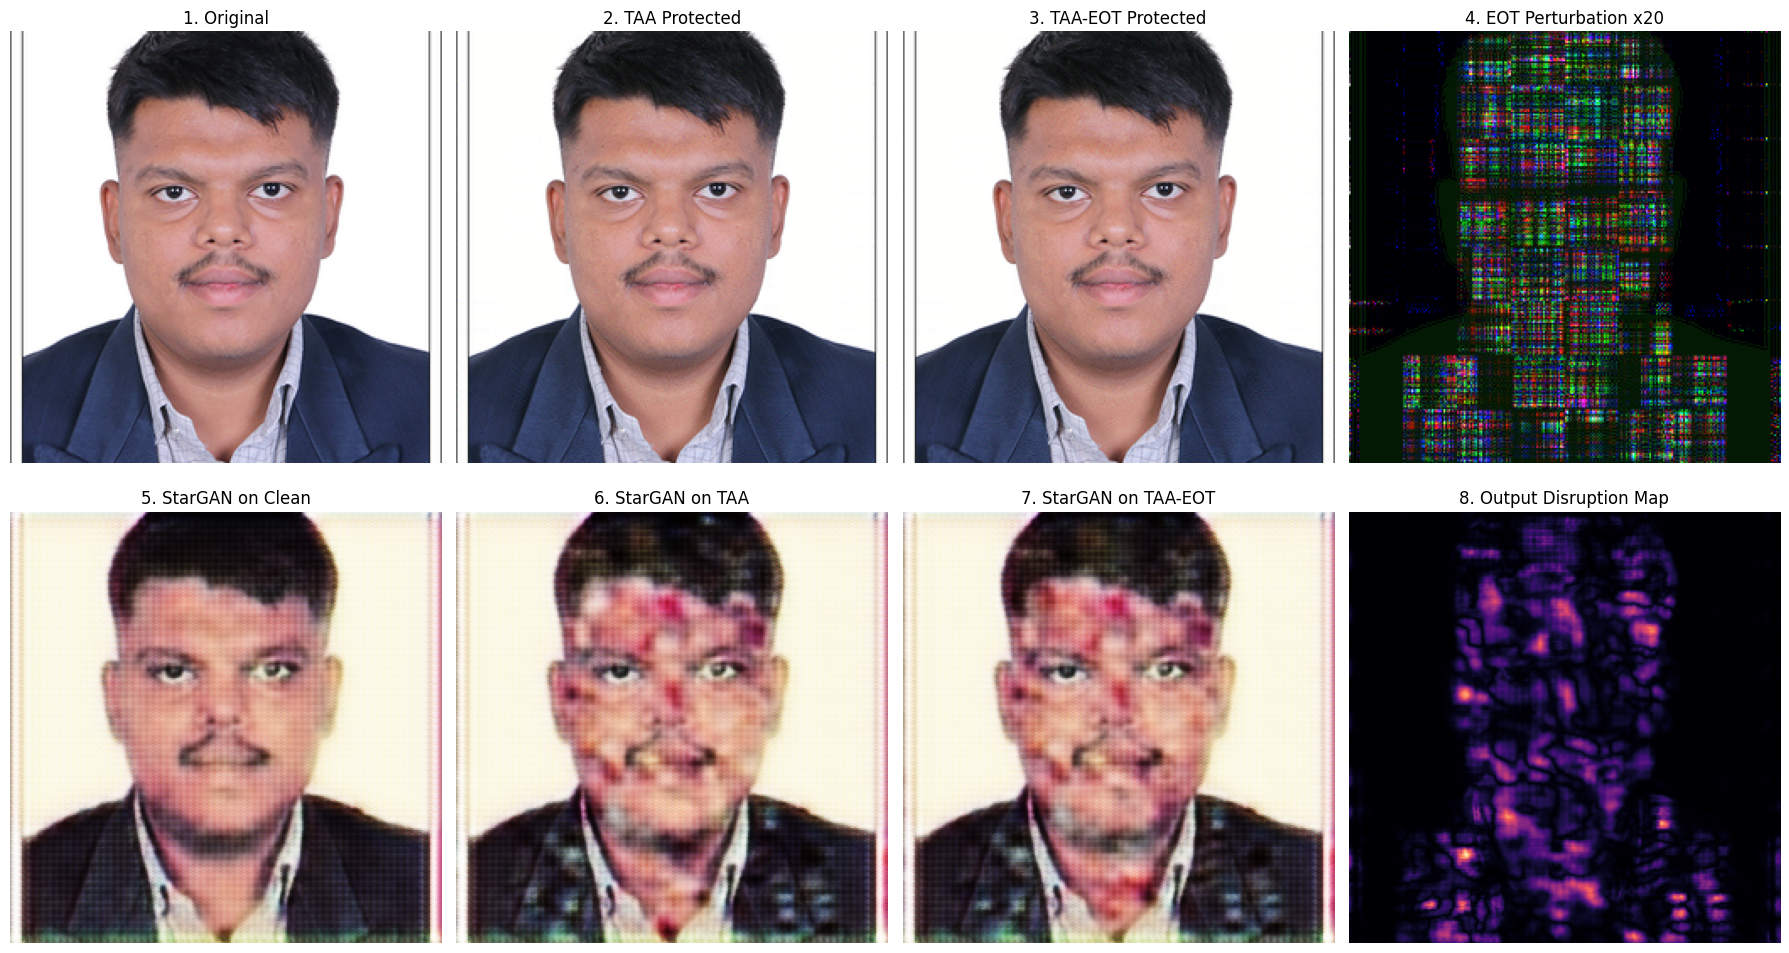

Saved: /content/taa_deepfake_defense/outputs/final_demo_comparison.png


In [14]:
fig, ax = plt.subplots(2, 4, figsize=(18, 10))
ax[0,0].imshow(tensor_to_np01(x_clean)); ax[0,0].set_title("1. Original")
ax[0,1].imshow(tensor_to_np01(x_taa));   ax[0,1].set_title("2. TAA Protected")
ax[0,2].imshow(tensor_to_np01(x_eot));   ax[0,2].set_title("3. TAA-EOT Protected")
ax[0,3].imshow(np.clip(np.abs(tensor_to_np01(x_eot) - tensor_to_np01(x_clean)) * 20, 0, 1))
ax[0,3].set_title("4. EOT Perturbation x20")

ax[1,0].imshow(tensor_to_np01(y_clean_ref)); ax[1,0].set_title("5. StarGAN on Clean")
ax[1,1].imshow(tensor_to_np01(y_taa));       ax[1,1].set_title("6. StarGAN on TAA")
ax[1,2].imshow(tensor_to_np01(y_eot));       ax[1,2].set_title("7. StarGAN on TAA-EOT")

out_diff = np.mean(np.abs(tensor_to_np01(y_clean_ref) - tensor_to_np01(y_eot)), axis=2)
ax[1,3].imshow(out_diff, cmap="magma"); ax[1,3].set_title("8. Output Disruption Map")

for a in ax.ravel():
    a.axis("off")
plt.tight_layout()
demo_fig_path = OUTPUTS / "final_demo_comparison.png"
plt.savefig(demo_fig_path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", demo_fig_path)

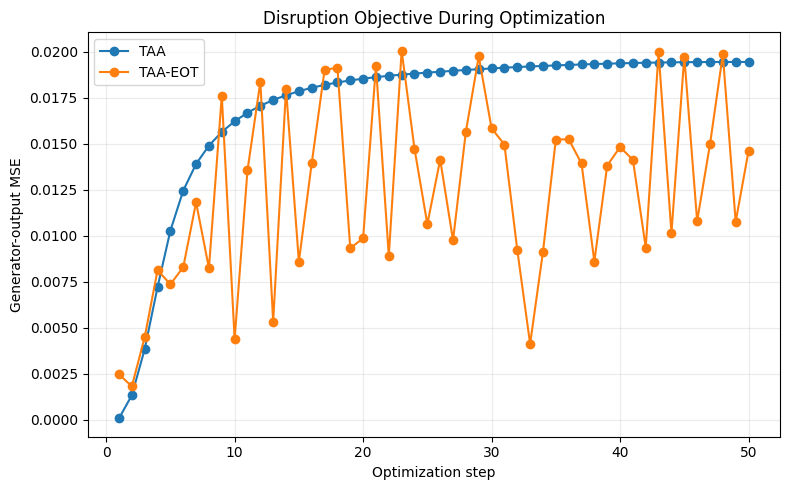

Saved: /content/taa_deepfake_defense/outputs/optimization_curve.png


In [15]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(taa_history) + 1), taa_history, marker="o", label="TAA")
plt.plot(range(1, len(eot_history) + 1), eot_history, marker="o", label="TAA-EOT")
plt.xlabel("Optimization step"); plt.ylabel("Generator-output MSE")
plt.title("Disruption Objective During Optimization")
plt.grid(True, alpha=0.25); plt.legend(); plt.tight_layout()
curve_path = OUTPUTS / "optimization_curve.png"
plt.savefig(curve_path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", curve_path)

In [16]:
def save_tensor_png(x, path):
    tensor_to_pil(x).save(path, format="PNG")

def save_tensor_jpeg(x, path, quality=70):
    tensor_to_pil(x).save(path, format="JPEG", quality=quality, optimize=True)

taa_png = OUTPUTS / "protected_TAA.png"
eot_png = OUTPUTS / "protected_TAA_EOT.png"
eot_jpg = OUTPUTS / "protected_TAA_EOT_Q70.jpg"

save_tensor_png(x_taa, taa_png)
save_tensor_png(x_eot, eot_png)
save_tensor_jpeg(x_eot, eot_jpg, quality=70)
np.save(OUTPUTS / "delta_TAA_EOT.npy", delta_eot.detach().cpu().numpy())

print("Files created:")
for p in [taa_png, eot_png, eot_jpg]:
    print(" -", p, f"({p.stat().st_size/1024:.1f} KB)")

print("\nRunning the next cell downloads protected_TAA_EOT.png to your computer.")

Files created:
 - /content/taa_deepfake_defense/outputs/protected_TAA.png (92.0 KB)
 - /content/taa_deepfake_defense/outputs/protected_TAA_EOT.png (91.9 KB)
 - /content/taa_deepfake_defense/outputs/protected_TAA_EOT_Q70.jpg (8.1 KB)

Running the next cell downloads protected_TAA_EOT.png to your computer.


In [17]:
files.download(str(eot_png))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Actual JPEG Q=70 output MSE:  0.002371
Actual JPEG Q=70 output PSNR: 32.27 dB


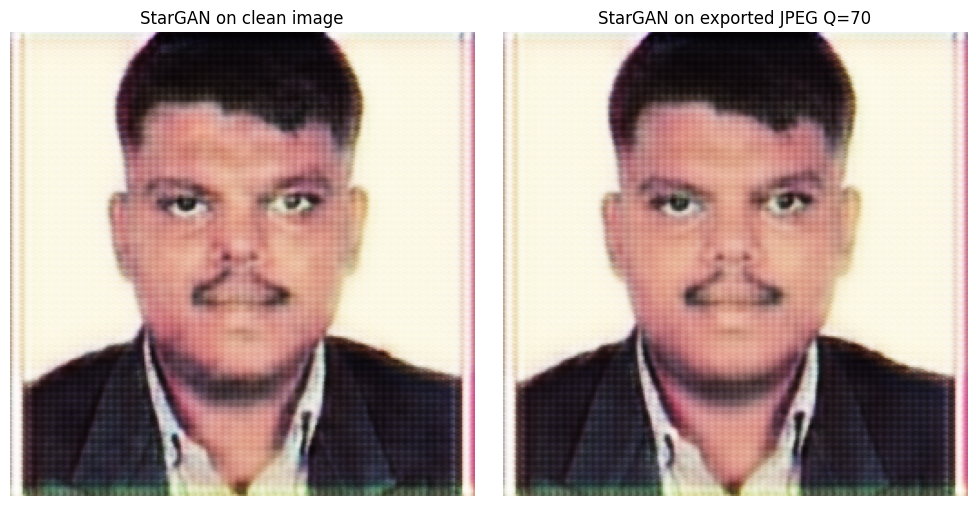

In [18]:
def load_saved_image_as_tensor(path):
    img = Image.open(path).convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.LANCZOS)
    x = transforms.ToTensor()(img).unsqueeze(0).to(DEVICE)
    return x * 2.0 - 1.0

x_jpeg = load_saved_image_as_tensor(eot_jpg)
with torch.no_grad():
    y_jpeg = G(x_jpeg, c_target)

jpeg_mse = float(F.mse_loss(y_clean_ref, y_jpeg).cpu())
jpeg_out_psnr = psnr01(y_clean_ref, y_jpeg)
print(f"Actual JPEG Q=70 output MSE:  {jpeg_mse:.6f}")
print(f"Actual JPEG Q=70 output PSNR: {jpeg_out_psnr:.2f} dB")
display_pair(y_clean_ref, y_jpeg, titles=("StarGAN on clean image", "StarGAN on exported JPEG Q=70"))

In [19]:
def jpeg_roundtrip(x, quality):
    buf = io.BytesIO(); tensor_to_pil(x).save(buf, format="JPEG", quality=quality); buf.seek(0)
    img = Image.open(buf).convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.LANCZOS)
    return transforms.ToTensor()(img).unsqueeze(0).to(DEVICE) * 2.0 - 1.0

def resize_roundtrip(x, size=224):
    img = tensor_to_pil(x)
    back = img.resize((size, size), Image.Resampling.LANCZOS).resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.LANCZOS)
    return transforms.ToTensor()(back).unsqueeze(0).to(DEVICE) * 2.0 - 1.0

def blur_roundtrip(x, radius=1.0):
    blurred = tensor_to_pil(x).filter(ImageFilter.GaussianBlur(radius=radius))
    return transforms.ToTensor()(blurred).unsqueeze(0).to(DEVICE) * 2.0 - 1.0

robust_cases = [
    ("PNG", x_eot), ("JPEG_Q90", jpeg_roundtrip(x_eot, 90)), ("JPEG_Q70", jpeg_roundtrip(x_eot, 70)),
    ("JPEG_Q50", jpeg_roundtrip(x_eot, 50)), ("Resize_224", resize_roundtrip(x_eot, 224)),
    ("Blur_1.0", blur_roundtrip(x_eot, 1.0)),
]

rows = []
with torch.no_grad():
    for name, xt in robust_cases:
        yt = G(xt, c_target)
        rows.append({"Transformation": name,
                     "Output_MSE": float(F.mse_loss(y_clean_ref, yt).cpu()),
                     "Output_PSNR_dB": psnr01(y_clean_ref, yt)})

robust_df = pd.DataFrame(rows)
display(robust_df.round(6))
robust_csv = OUTPUTS / "robustness_results.csv"
robust_df.to_csv(robust_csv, index=False)
print("Saved:", robust_csv)

,Transformation,Output_MSE,Output_PSNR_dB
0,PNG,0.019917,23.028409
1,JPEG_Q90,0.002163,32.669926
2,JPEG_Q70,0.002371,32.271384
3,JPEG_Q50,0.002933,31.347045
4,Resize_224,0.002814,31.527253
5,Blur_1.0,0.004487,29.501230


Saved: /content/taa_deepfake_defense/outputs/robustness_results.csv


In [20]:
def pgd_baseline(x, c_target, generator, num_steps=50, lr=0.01, epsilon_px=0.05):
    delta = torch.zeros_like(x, requires_grad=True)
    optimizer = torch.optim.Adam([delta], lr=lr)
    with torch.no_grad():
        y_ref = generator(x, c_target).detach()

    hist = []
    for step in range(num_steps):
        optimizer.zero_grad(set_to_none=True)
        x_adv = torch.clamp(x + delta, -1, 1)
        y_adv = generator(x_adv, c_target)
        disruption = F.mse_loss(y_adv, y_ref)
        (-disruption).backward()
        optimizer.step()
        with torch.no_grad():
            delta.clamp_(-epsilon_px, epsilon_px)
        hist.append(float(disruption.detach().cpu()))

    with torch.no_grad():
        x_out = torch.clamp(x + delta.detach(), -1, 1)
        y_out = generator(x_out, c_target)
    return x_out, y_out, hist

x_pgd, y_pgd, pgd_history = pgd_baseline(x_clean, c_target, G, num_steps=NUM_STEPS, lr=0.01, epsilon_px=EPSILON)
pgd_result = evaluate_method(x_clean, x_pgd, y_clean_ref, y_pgd, "Vanilla-PGD")
comparison = pd.concat([results, pd.DataFrame([pgd_result])], ignore_index=True)
display(comparison.round(6))

,Method,Input_PSNR_dB,Input_SSIM,Input_LPIPS,Input_L1,Input_L2_Fro,Input_L2_RMS,Output_MSE,Output_L1,Output_L2_Fro,Output_L2_RMS,Output_PSNR_dB
0,TAA,40.053446,0.960040,0.001447,0.010992,8.813701,0.019877,0.019453,0.072772,61.843975,0.139475,23.130664
1,TAA-EOT,40.248095,0.961766,0.001497,0.010750,8.618383,0.019437,0.019917,0.073450,62.576332,0.141127,23.028409
2,Vanilla-PGD,33.765319,0.861522,0.003097,0.034725,18.178780,0.040998,1.419778,0.978579,528.336731,1.191544,4.498396


In [21]:
summary = comparison.copy()
jpeg_row = {"Method": "TAA-EOT + actual JPEG Q70", "Input_PSNR_dB": np.nan, "Input_SSIM": np.nan,
            "Input_LPIPS": np.nan, "Input_L1": np.nan, "Input_L2_Fro": np.nan, "Input_L2_RMS": np.nan,
            "Output_MSE": jpeg_mse, "Output_L1": np.nan, "Output_L2_Fro": np.nan, "Output_L2_RMS": np.nan,
            "Output_PSNR_dB": jpeg_out_psnr}
summary = pd.concat([summary, pd.DataFrame([jpeg_row])], ignore_index=True)

summary_csv = OUTPUTS / "final_metrics.csv"
summary.to_csv(summary_csv, index=False)

config_txt = OUTPUTS / "experiment_config.txt"
config_txt.write_text("\n".join([
    f"Image size: {IMAGE_SIZE}", f"Grid size: {GRID_SIZE}", f"Tail rank: {TAIL_RANK}",
    f"SVD amplification: {SVD_AMPLIFICATION}", f"Epsilon (single budget, see Step 10 fix): {EPSILON}",
    f"Iterations: {NUM_STEPS}", f"Learning rate: {LEARNING_RATE}", f"Color noise std: {COLOR_NOISE_STD}",
    f"EOT enabled: {USE_EOT}", f"EOT samples: {EOT_SAMPLES}",
    f"Target attribute: {TARGET_ATTRIBUTE}={TARGET_VALUE}",
    f"Generator checkpoint source: {checkpoint_source if USING_REAL_STARGAN else 'PLACEHOLDER (no real checkpoint)'}",
]))

zip_path = OUTPUTS / "TAA_EOT_demo_artifacts.zip"
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as z:
    for p in [taa_png, eot_png, eot_jpg, demo_fig_path, curve_path, robust_csv, summary_csv, config_txt,
              OUTPUTS / "delta_TAA_EOT.npy"]:
        if p.exists():
            z.write(p, arcname=p.name)

print("Research artifacts:")
for p in [summary_csv, config_txt, demo_fig_path, curve_path, robust_csv, zip_path]:
    print(" -", p)
display(summary.round(6))

Research artifacts:
 - /content/taa_deepfake_defense/outputs/final_metrics.csv
 - /content/taa_deepfake_defense/outputs/experiment_config.txt
 - /content/taa_deepfake_defense/outputs/final_demo_comparison.png
 - /content/taa_deepfake_defense/outputs/optimization_curve.png
 - /content/taa_deepfake_defense/outputs/robustness_results.csv
 - /content/taa_deepfake_defense/outputs/TAA_EOT_demo_artifacts.zip


/tmp/ipykernel_774/2285678019.py:6: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  summary = pd.concat([summary, pd.DataFrame([jpeg_row])], ignore_index=True)


,Method,Input_PSNR_dB,Input_SSIM,Input_LPIPS,Input_L1,Input_L2_Fro,Input_L2_RMS,Output_MSE,Output_L1,Output_L2_Fro,Output_L2_RMS,Output_PSNR_dB
0,TAA,40.053446,0.960040,0.001447,0.010992,8.813701,0.019877,0.019453,0.072772,61.843975,0.139475,23.130664
1,TAA-EOT,40.248095,0.961766,0.001497,0.010750,8.618383,0.019437,0.019917,0.073450,62.576332,0.141127,23.028409
2,Vanilla-PGD,33.765319,0.861522,0.003097,0.034725,18.178780,0.040998,1.419778,0.978579,528.336731,1.191544,4.498396
3,TAA-EOT + actual JPEG Q70,NaN,NaN,NaN,NaN,NaN,NaN,0.002371,NaN,NaN,NaN,32.271384


In [22]:
files.download(str(zip_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
RUN_BATCH = False
BATCH_METHOD = "TAA-EOT"   # "TAA" or "TAA-EOT"
MAX_IMAGES = 20

if RUN_BATCH:
    batch_uploaded = files.upload()
    batch_names = list(batch_uploaded.keys())[:MAX_IMAGES]
    if not batch_names:
        raise RuntimeError("No batch images uploaded.")

    batch_dir = INPUTS / "batch"; batch_dir.mkdir(exist_ok=True)
    batch_rows = []
    for idx, name in enumerate(batch_names, 1):
        p = batch_dir / name
        with open(p, "wb") as f:
            f.write(batch_uploaded[name])
        try:
            _, xb = load_image_tensor(p, IMAGE_SIZE)
            use_eot_b = (BATCH_METHOD == "TAA-EOT")
            xb_prot, db, yb_clean, yb_prot, _ = optimize_protection(
                xb, c_target, G, use_eot=use_eot_b, eot_samples=EOT_SAMPLES if use_eot_b else 1,
                num_steps=NUM_STEPS, lr=LEARNING_RATE, epsilon=EPSILON, grid=GRID_SIZE,
                tail_rank=TAIL_RANK, amplification=SVD_AMPLIFICATION, color_noise_std=COLOR_NOISE_STD)
            row = evaluate_method(xb, xb_prot, yb_clean, yb_prot, BATCH_METHOD)
            row["Image"] = name
            batch_rows.append(row)
            save_tensor_png(xb_prot, OUTPUTS / f"protected_{idx:03d}.png")
            print(f"[{idx}/{len(batch_names)}] {name} done.")
            del xb, xb_prot, yb_clean, yb_prot, db
            torch.cuda.empty_cache()
        except Exception as exc:
            print("FAILED:", name, "|", repr(exc))

    batch_df = pd.DataFrame(batch_rows)
    display(batch_df.round(6))
    mean_row = batch_df.select_dtypes(include=[np.number]).mean().to_frame().T
    std_row = batch_df.select_dtypes(include=[np.number]).std(ddof=1).to_frame().T
    mean_row.insert(0, "Statistic", "mean"); std_row.insert(0, "Statistic", "std")
    summary_batch = pd.concat([mean_row, std_row], ignore_index=True)
    display(summary_batch.round(6))
    batch_df.to_csv(OUTPUTS / "batch_per_image_metrics.csv", index=False)
    summary_batch.to_csv(OUTPUTS / "batch_mean_std.csv", index=False)
    print("Saved batch results to outputs/.")
else:
    print("RUN_BATCH=False -- skipped. Set True for the paper-scale experiment.")

RUN_BATCH=False -- skipped. Set True for the paper-scale experiment.


In [24]:
checks = {
    "StarGAN checkpoint used (real, not placeholder)": USING_REAL_STARGAN,
    "Original input": input_path.exists(),
    "TAA PNG": taa_png.exists(),
    "TAA-EOT PNG": eot_png.exists(),
    "TAA-EOT JPEG Q70": eot_jpg.exists(),
    "Final metrics CSV": (OUTPUTS / "final_metrics.csv").exists(),
    "Robustness CSV": robust_csv.exists(),
    "Demo comparison figure": demo_fig_path.exists(),
}
print("FINAL DEMO VERIFICATION"); print("=" * 40)
for k, v in checks.items():
    print(f"{'PASS' if v else 'FAIL'}  {k}")

print("\nProtected file:", eot_png)
print("JPEG test file:", eot_jpg)
print("Use only permissioned/authorized face images and test services.")

FINAL DEMO VERIFICATION
PASS  StarGAN checkpoint used (real, not placeholder)
PASS  Original input
PASS  TAA PNG
PASS  TAA-EOT PNG
PASS  TAA-EOT JPEG Q70
PASS  Final metrics CSV
PASS  Robustness CSV
PASS  Demo comparison figure

Protected file: /content/taa_deepfake_defense/outputs/protected_TAA_EOT.png
JPEG test file: /content/taa_deepfake_defense/outputs/protected_TAA_EOT_Q70.jpg
Use only permissioned/authorized face images and test services.
